In [27]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import ast

In [29]:
# Read in woke
wokeGames = pd.read_csv("Data/wokeGames.csv")
wokeGames.drop(columns=["Unnamed: 0"], inplace=True)

notWokeGames = pd.read_csv("Data/notWokeGames.csv")
notWokeGames.drop(columns=["Unnamed: 0"], inplace=True)


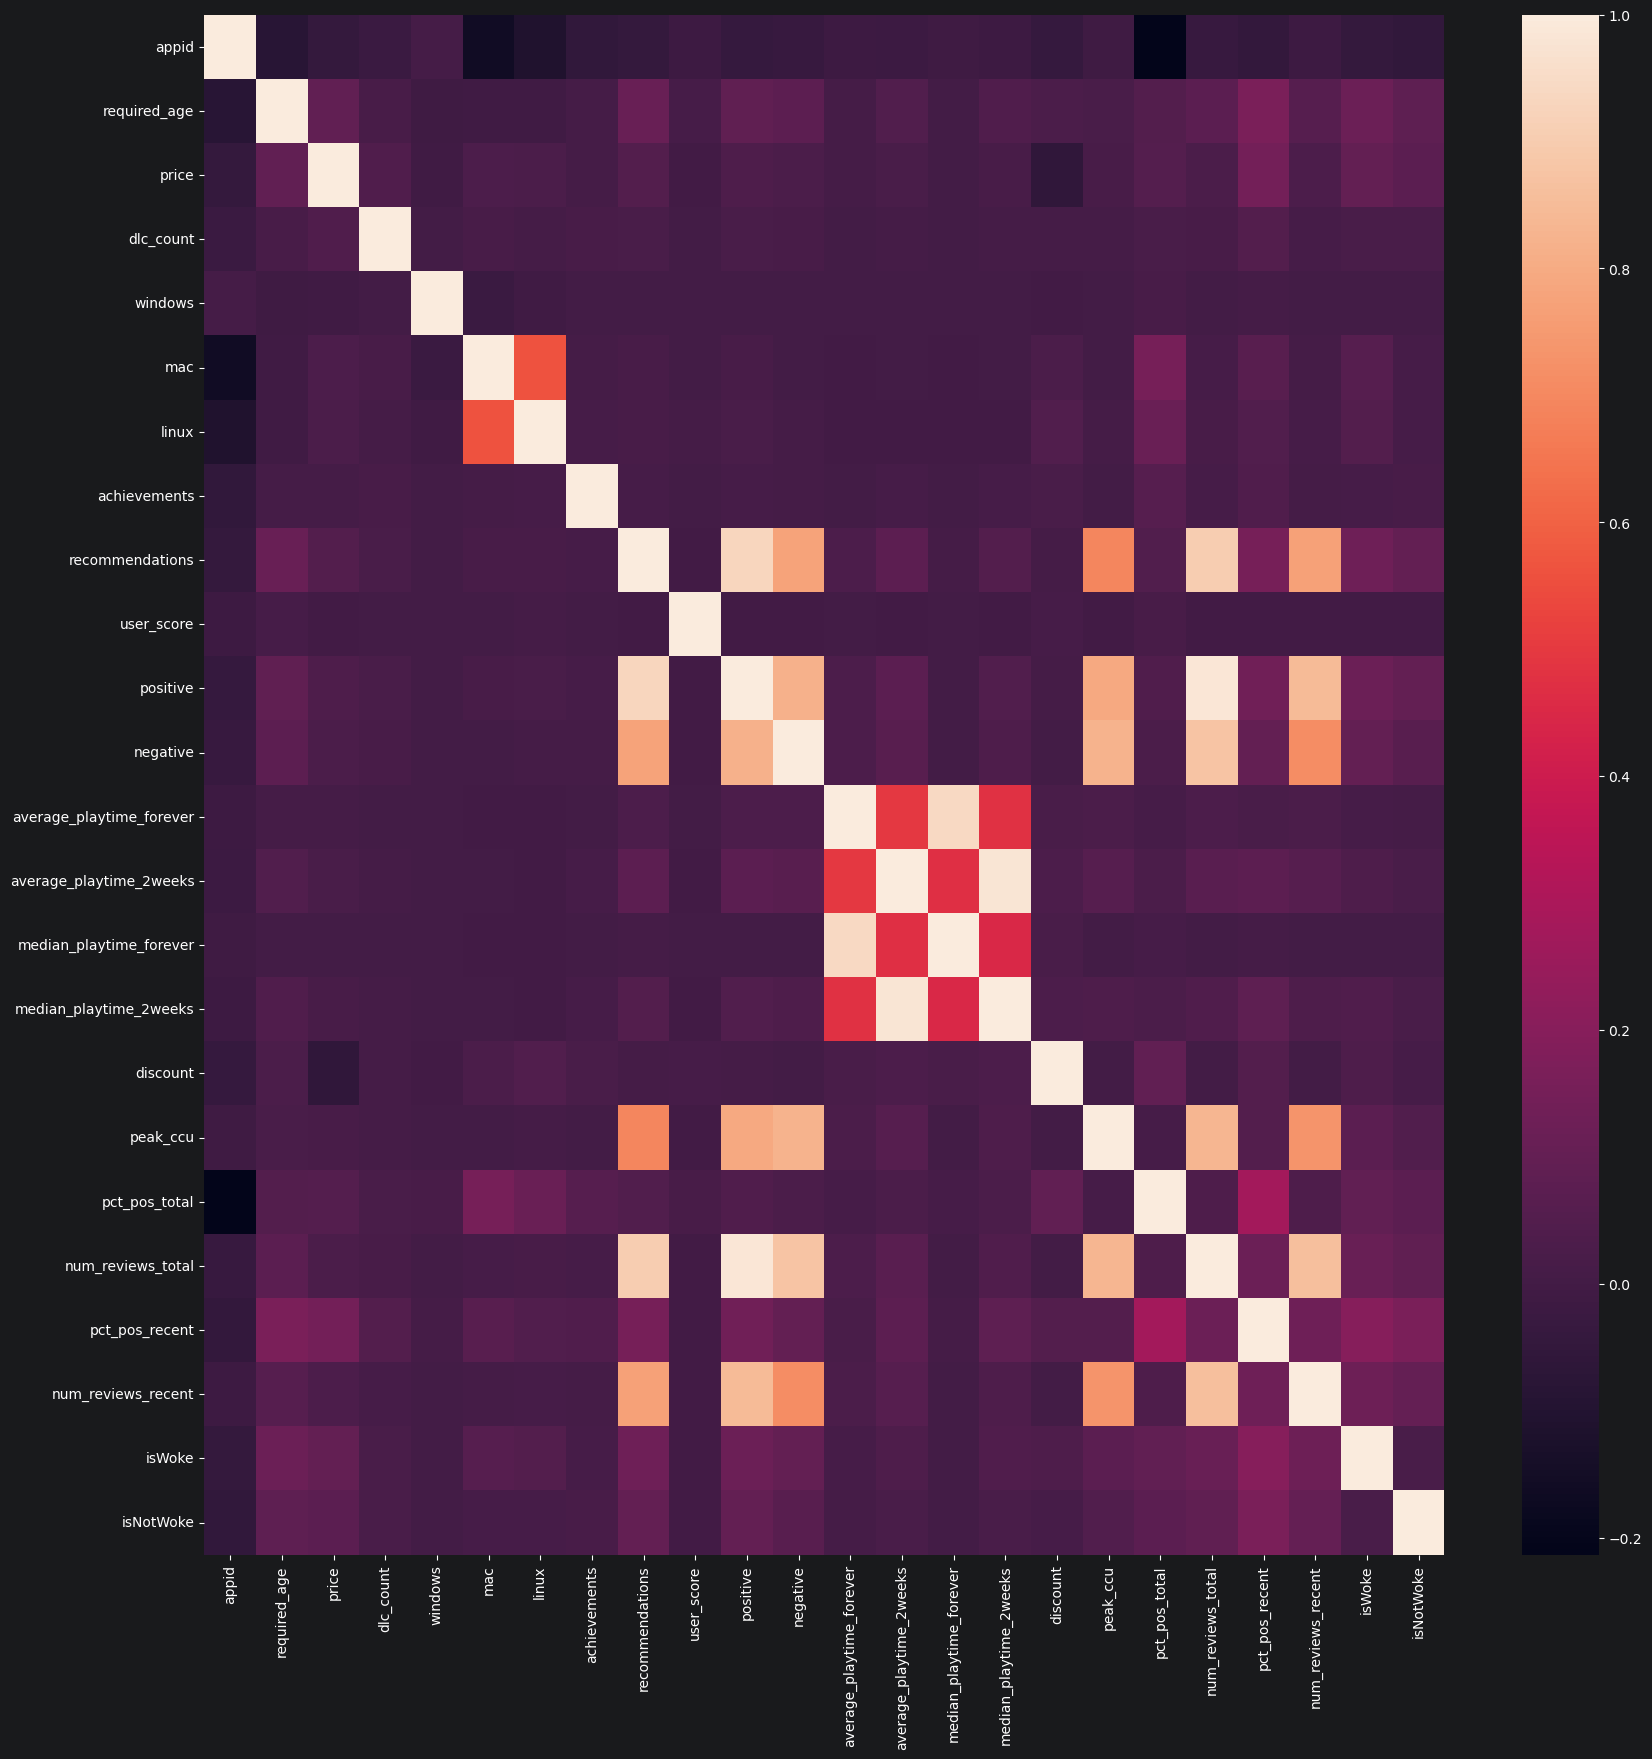

In [30]:
# Read in file
steam = pd.read_csv("Data/games_march2025_cleaned.csv")
steam = steam.drop(columns=["about_the_game", "release_date", "short_description",
                            "detailed_description", "support_url", "support_email",
                            "website", "reviews", "metacritic_score", "metacritic_url",
                            "notes", "score_rank", "header_image", "packages", "developers", "publishers",
                            "screenshots", "movies", "estimated_owners", "name", "tags"]) #NEED TO WRITE SOMETHING FOR TAGS
steam["isWoke"] = steam["appid"].isin(wokeGames["0"])
steam["isNotWoke"] = steam["appid"].isin(notWokeGames["0"])

steam_temp = steam.drop(columns=["supported_languages", "full_audio_languages", "categories", "genres"])
correlation_matrix = steam_temp.corr()
plt.figure(figsize=(20,20))
sns.heatmap(correlation_matrix, fmt="g")
plt.show()


In [ ]:
def dummyVariable(name_of_feature):
    global steam
    steam["temp"] = steam[name_of_feature].apply(ast.literal_eval)
    exploded_languages = steam["temp"].explode()
    # turn many values of the same langauge from the explosion into "max", whether it supports that language or not
    dummies_languages = pd.get_dummies(exploded_languages).groupby(level=0).max()
    dummies_languages.columns += "_" + name_of_feature
    #print(dummies_languages.head())
    steam = pd.concat([steam, dummies_languages], axis=1)
    steam.drop(columns=["temp", name_of_feature], inplace=True)

dummyVariable("supported_languages")
dummyVariable("full_audio_languages")
dummyVariable("categories")
dummyVariable("genres")


In [35]:
print(steam.shape)
print(steam.head())
print(steam.info())
#print(steam.iloc[50000].info())

print(steam["isWoke"].sum())
print(steam["isNotWoke"].sum())

(89618, 28)
    appid  required_age  price  dlc_count  windows    mac  linux  \
0     730             0   0.00          1     True  False   True   
1  578080             0   0.00          0     True  False  False   
2     570             0   0.00          2     True   True   True   
3  271590            17   0.00          0     True  False  False   
4  359550            17   3.99          9     True  False  False   

   achievements  recommendations  \
0             1          4401572   
1            37          1732007   
2             0            14337   
3            77          1803063   
4             0          1165929   

                                 supported_languages  ...  \
0  ['Czech', 'Danish', 'Dutch', 'English', 'Finni...  ...   
1  ['English', 'Korean', 'Simplified Chinese', 'F...  ...   
2  ['Bulgarian', 'Czech', 'Danish', 'Dutch', 'Eng...  ...   
3  ['English', 'French', 'Italian', 'German', 'Sp...  ...   
4  ['English', 'French', 'Italian', 'German', 'Sp...  ...

In [ ]:
correlation_matrix = steam.corr()
correlation_matrix.to_csv("correlation.csv")
#print(correlation_matrix)
#plt.figure(figsize=(20,20))
#sns.heatmap(correlation_matrix, fmt="g")
#plt.show()